In [2]:
import numpy as np
#import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

### Manifold: Circle

In [3]:
N = 10000 #sample size
r = 1 #radius

t_max = 4 * np.pi
u = np.random.uniform(0, 1, N)
t = t_max * np.sqrt(u)
x = r * np.cos(t)
y = r * np.sin(t)

dataset = np.column_stack((x, y))
t_domain = np.linspace(0, 2*np.pi, 1000)
manifold = np.column_stack((r*np.cos(t_domain),r*np.sin(t_domain)))

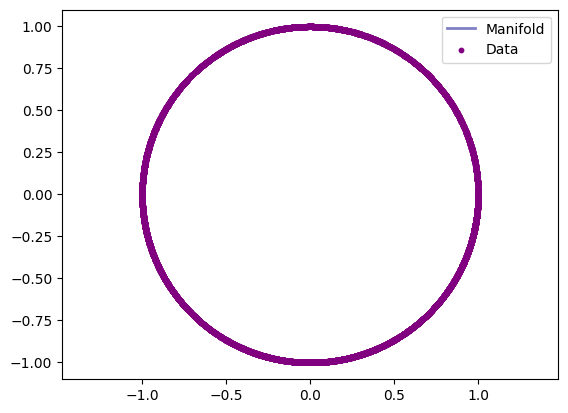

In [4]:
#100 points for visualization purposes
plt.plot(manifold[:,0], manifold[:,1], c = 'darkblue', linewidth = 2, label = 'Manifold', zorder = 1, alpha = 0.5)
plt.scatter(x = dataset[:,0], y = dataset[:,1], c = 'purple', s = 10, alpha = 1, label = 'Data', zorder = 2)
plt.axis('equal') 
plt.legend()
plt.show()

### Manifold: Spiral

In [18]:
N = 10000 #sample size
c = 0.5

t_max = 4 * np.pi
u = np.random.uniform(0, 1, N)
t = t_max * np.sqrt(u)
x = c * t * np.cos(t)
y = c * t * np.sin(t)
dataset = np.column_stack((x, y))

t_domain = np.linspace(0, 4*np.pi, 1000)
manifold = np.column_stack((c*np.cos(t_domain)*t_domain,c*np.sin(t_domain)*t_domain))
manifold = (manifold - np.mean(dataset, axis=0)) / np.std(dataset, axis=0) #manif standardized
dataset = (dataset - np.mean(dataset, axis=0)) / np.std(dataset, axis=0) #data standardized

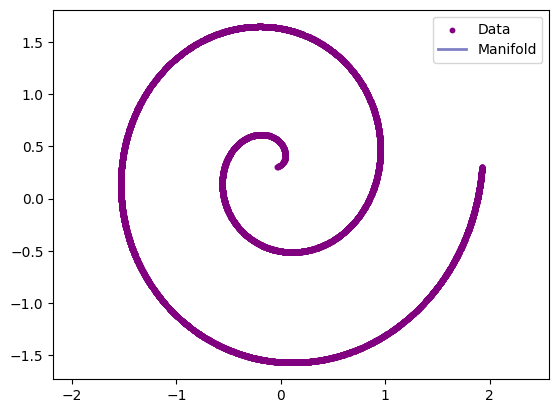

In [19]:
plt.scatter(x = dataset[:,0], y = dataset[:,1], c = 'purple', s = 10, alpha = 1, label = 'Data', zorder = 2)
plt.plot(manifold[:,0], manifold[:,1], c = 'darkblue', linewidth = 2, label = 'Manifold', zorder = 1, alpha = .5)
plt.axis('equal') 
plt.legend()
plt.show()

#### We see that a huge part of the manifold is modeled by a small part of the time interval from which we are sampling uniformly

### Manifold: Staright Line

In [73]:
N = 1000 # sample size
length = 10.0 # length of the line
t = np.random.uniform(-length/2, length/2, N)
x = t + np.random.normal(scale=0.1, size=N)
y = np.zeros(N) 

dataset = np.column_stack((x, y))
t_domain = np.linspace(-length/2, length/2, 1000)
manifold = np.column_stack((t_domain, np.zeros(1000)))

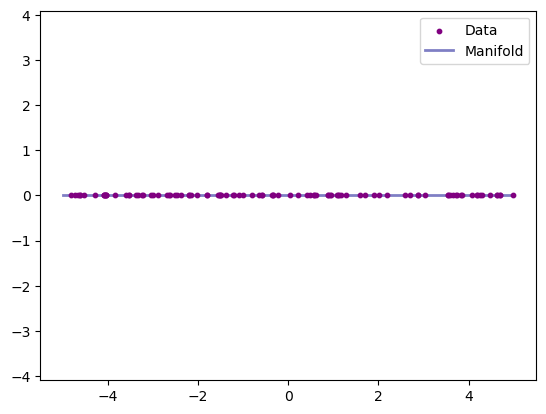

In [72]:
plt.scatter(x = dataset[:,0], y = dataset[:,1], c = 'purple', s = 10, alpha = 1, label = 'Data', zorder = 2)
plt.plot(manifold[:,0], manifold[:,1], c = 'darkblue', linewidth = 2, label = 'Manifold', zorder = 1, alpha = .5)
plt.axis('equal') 
plt.legend()
plt.show()

### Manifold: S-shape

In [49]:
N = 1000

#using arclengths tp sample uniformly
y_dense = np.linspace(-2, 2, 10000)
x_dense = np.sin(y_dense * (np.pi / 2))
deltas = np.sqrt(np.diff(x_dense)**2 + np.diff(y_dense)**2)
cumulative_distance = np.concatenate(([0], np.cumsum(deltas)))
total_length = cumulative_distance[-1]
random_distances = np.random.uniform(0, total_length, N)
y_val = np.interp(random_distances, cumulative_distance, y_dense)
x_val = np.sin(y_val * (np.pi / 2))

# Combine into your final dataset
dataset = np.column_stack((x_val, y_val))

y_domain = np.linspace(-2, 2, 1000)
manifold = np.column_stack((np.sin(y_domain * (np.pi / 2)), y_domain))

manifold = (manifold - np.mean(dataset, axis=0)) / np.std(dataset, axis=0) #manif standardized
dataset = (dataset - np.mean(dataset, axis=0)) / np.std(dataset, axis=0) #data standardized

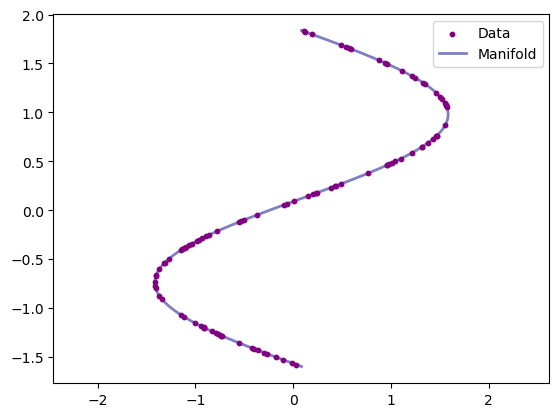

In [48]:
plt.scatter(x = dataset[:,0], y = dataset[:,1], c = 'purple', s = 10, alpha = 1, label = 'Data', zorder = 2)
plt.plot(manifold[:,0], manifold[:,1], c = 'darkblue', linewidth = 2, label = 'Manifold', zorder = 1, alpha = .5)
plt.axis('equal') 
plt.legend()
plt.show()

### Forward Gaussian and NN Architecture

In [5]:
def time_embedding(t, dim=32):
    """NECESSAITY BECAUSe THE CURVATURE IS NONLINEAR OVER TIME USUALLY"""
    freqs = torch.exp(
        torch.linspace(0, np.log(1000), dim//2)
    )
    args = t * freqs[None, :]
    return torch.cat([t*torch.sin(args), t*torch.cos(args)], dim=-1)
class score_nn(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(34,256),
            nn.ReLU(),
            nn.Linear(256,512),
            nn.ReLU(),
            nn.Linear(512,256),
            nn.ReLU(),
            nn.Linear(256,2))
    def forward(self, x_noisy, t):
        t_emb = time_embedding(t)
        input_features = torch.cat([x_noisy, t_emb], dim=1) 
        return self.net(input_features)

In [20]:
model = score_nn() #model initialization
L2loss = nn.MSELoss() #L2 loss
optimizer = optim.Adam(model.parameters(), lr=1e-3) #optimizer
sigma_q = 0.5 #terminal sigma from the paper, NOT PER-STEP ???
# Conver clean manifold to a tensor
data_tens = torch.tensor(dataset, dtype=torch.float32) #data in tensor form
epochs = 2000

for epoch in range(epochs):
    optimizer.zero_grad()
    #Sample random times for all points between 0 and 1
    t = torch.rand(N, 1) 
    noise = torch.randn(N, 2) #save true noise
    #Forward Process
    x_t = data_tens + noise * torch.sqrt(t)*sigma_q
    #predict noise
    noise_pred = model(x_t, t)
    #L2 loss
    L = L2loss(noise_pred, noise * torch.sqrt(t)*sigma_q)
    #updating weights
    L.backward()
    optimizer.step()
    
    if epoch % 200 == 0:
        print(f"Epoch {epoch} | Loss: {L.item()}")

Epoch 0 | Loss: 0.12534387409687042
Epoch 200 | Loss: 0.08949220925569534
Epoch 400 | Loss: 0.0881214290857315
Epoch 600 | Loss: 0.08722065389156342
Epoch 800 | Loss: 0.08888430893421173
Epoch 1000 | Loss: 0.08657270669937134
Epoch 1200 | Loss: 0.09001033008098602
Epoch 1400 | Loss: 0.08715888857841492
Epoch 1600 | Loss: 0.08967246115207672
Epoch 1800 | Loss: 0.0884125828742981


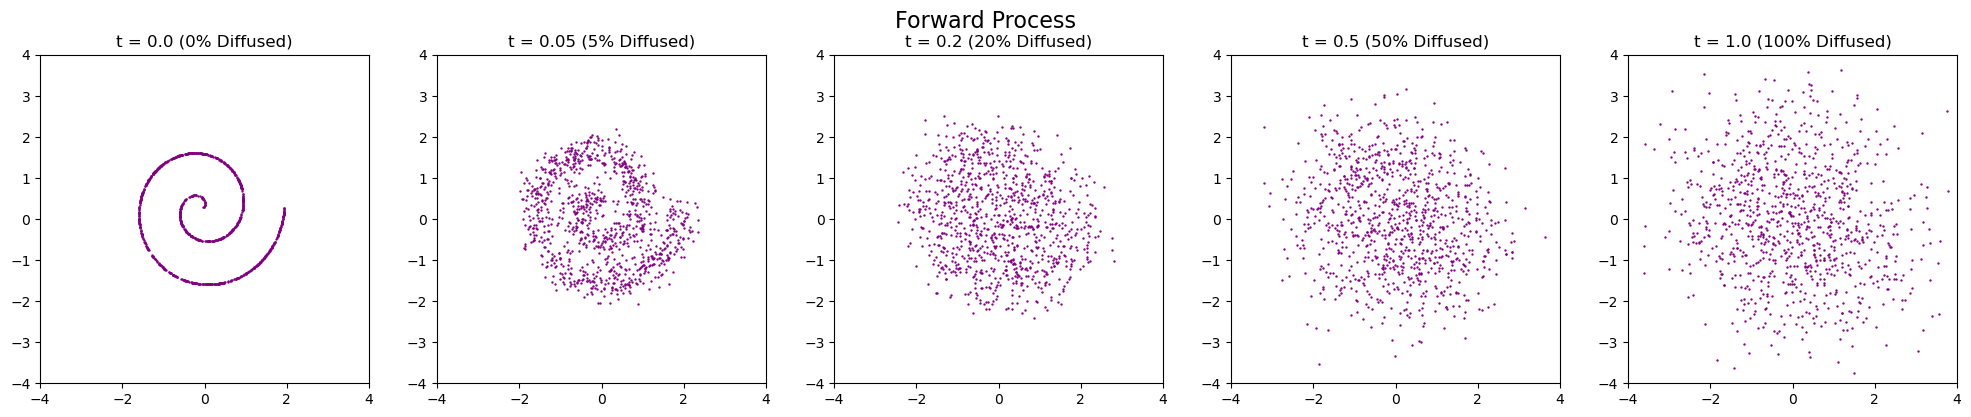

In [9]:
time_steps = [0.0, 0.05, 0.2, 0.5, 1.0]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i, t_val in enumerate(time_steps):
    noise = torch.randn(N, 2)
    
    x_t = data_tens + noise * torch.sqrt(torch.tensor(t_val))*sigma_q
    
    axes[i].scatter(x_t[:, 0].numpy(), x_t[:, 1].numpy(), s=0.5, color='purple', alpha=1)
    #axes[i].plot(manifold[:, 0], manifold[:, 1], color='purple', linewidth=2, alpha=0.8)
    axes[i].set_title(f"t = {t_val} ({(t_val*100):.0f}% Diffused)")
    
    axes[i].set_xlim(-4, 4); axes[i].set_ylim(-4, 4)
    #axes[i].set_xlim(-2, 2); axes[i].set_ylim(-2, 2)
    
    axes[i].set_aspect('equal', adjustable='box') 

plt.suptitle("Forward Process", fontsize=16)
plt.tight_layout()
plt.show()

### DDIM Reverse Sampling

In [23]:
x = torch.randn(1000, 2)
dt = 0.001
t_current = 1

with torch.no_grad():
    while t_current > 0:
        t_tensor = torch.full((1000, 1), t_current) #tensored current time for each datapoint 
        eps = model(x, t_tensor)
        t_next = max(0.0, t_current - dt)
        #lmbda = (np.sqrt(t_current) - np.sqrt(t_next)) / np.sqrt(t_current)
        x = x - dt/(2*t_current) * eps
        t_current -= dt

### Staright Line

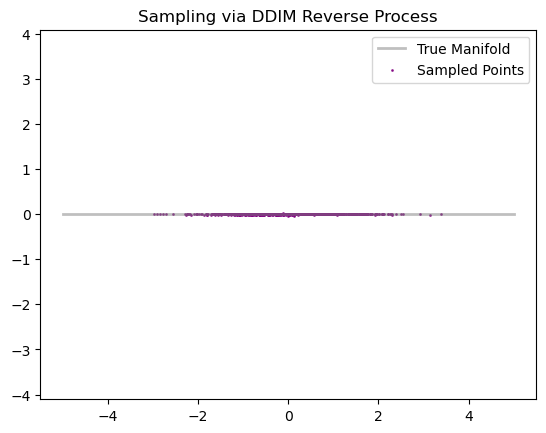

In [29]:
#plt.scatter(dataset[:, 0], dataset[:, 1], alpha=0.5, color='gray', label='Original Data')
plt.plot(manifold[:, 0], manifold[:, 1], color='gray', linewidth=2, label='True Manifold', alpha = .5)
plt.scatter(x[:, 0].numpy(), x[:, 1].numpy(), color='purple', s=1, alpha=0.8, label='Sampled Points')

plt.axis('equal')
plt.legend()
plt.title("Sampling via DDIM Reverse Process")
plt.show()

### Circle

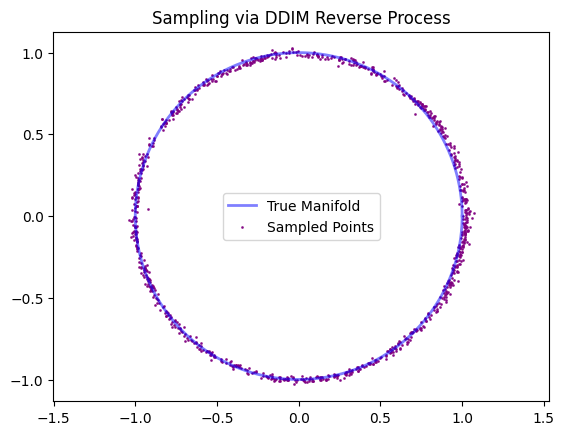

In [17]:
#plt.scatter(dataset[:, 0], dataset[:, 1], alpha=0.5, color='gray', label='Original Data')
plt.plot(manifold[:, 0], manifold[:, 1], color='blue', linewidth=2, label='True Manifold', alpha = .5)
plt.scatter(x[:, 0].numpy(), x[:, 1].numpy(), color='purple', s=1, alpha=0.8, label='Sampled Points')

plt.axis('equal')
plt.legend()
plt.title("Sampling via DDIM Reverse Process")
plt.show()

### S-shape

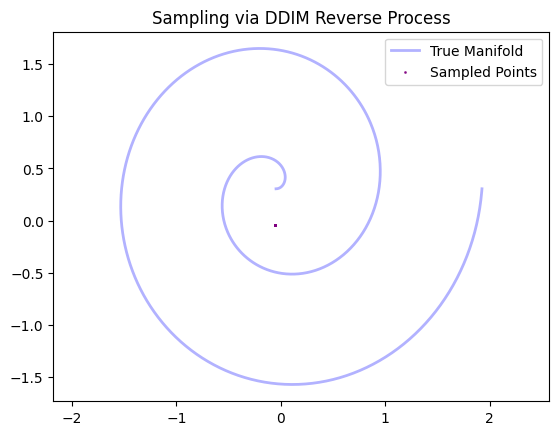

In [24]:
#plt.scatter(dataset[:, 0], dataset[:, 1], alpha=0.5, color='gray', label='Original Data')
plt.plot(manifold[:, 0], manifold[:, 1], color='blue', linewidth=2, label='True Manifold', alpha = .3)
plt.scatter(x[:, 0].numpy(), x[:, 1].numpy(), color='purple', s=1, alpha=0.8, label='Sampled Points')

plt.axis('equal')
plt.legend()
plt.title("Sampling via DDIM Reverse Process")
plt.show()

### Swiss Spiral

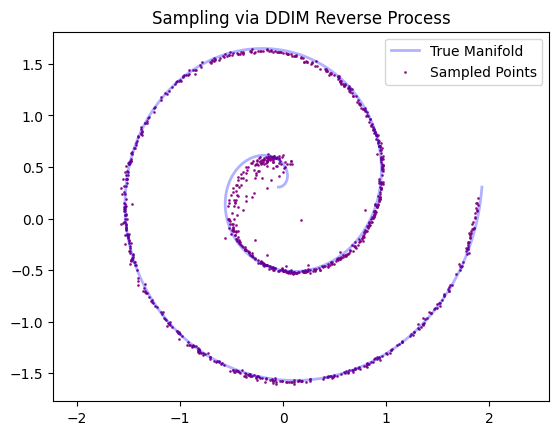

In [22]:
#plt.scatter(dataset[:, 0], dataset[:, 1], alpha=0.5, color='gray', label='Original Data')
plt.plot(manifold[:, 0], manifold[:, 1], color='blue', linewidth=2, label='True Manifold', alpha = .3)
plt.scatter(x[:, 0].numpy(), x[:, 1].numpy(), color='purple', s=1, alpha=0.8, label='Sampled Points')

plt.axis('equal')
plt.legend()
plt.title("Sampling via DDIM Reverse Process")
plt.show()